<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/mind_geographic_inr_distillation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Spatio-Temporal Spatial Gap Dataset Generator]
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"MIND Geographic INR Engine Initialized on: {device}")

class SpatialGapDatasetGenerator:
    """
    Generates synthetic 2D geographic coordinates and target spatial fields
    comprising both smooth macro-scale patterns and fine-scale local variations.
    Provides Random Holdout (interpolative) and Regional Spatial Gap Holdout splits.
    """
    def __init__(self, num_points: int = 2000):
        self.num_points = num_points

    def generate_data(self) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
        # Generate 2D coordinates in [-1, 1]^2
        coords = torch.empty(self.num_points, 2, device=device).uniform_(-1.0, 1.0)

        # Ground-truth continuous field: Macro smooth wave + Micro high-frequency variation
        macro_signal = torch.sin(2.5 * coords[:, 0]) + torch.cos(2.5 * coords[:, 1])
        micro_signal = 0.35 * torch.sin(12.0 * coords[:, 0]) * torch.cos(12.0 * coords[:, 1])
        targets = (macro_signal + micro_signal).unsqueeze(1)

        # Split 1: Random Holdout (80% Train, 20% Test)
        perm = torch.randperm(self.num_points)
        train_idx_rand = perm[:int(0.8 * self.num_points)]
        test_idx_rand = perm[int(0.8 * self.num_points):]

        # Split 2: Regional Spatial Gap Holdout (Exclude rectangular geographic region [-0.4, 0.4] x [0.0, 0.8])
        in_gap = (coords[:, 0] >= -0.4) & (coords[:, 0] <= 0.4) & (coords[:, 1] >= 0.0) & (coords[:, 1] <= 0.8)
        train_idx_gap = torch.where(~in_gap)[0]
        test_idx_gap = torch.where(in_gap)[0]

        return coords, targets, train_idx_rand, test_idx_rand, train_idx_gap, test_idx_gap

generator = SpatialGapDatasetGenerator(num_points=2000)
coords, targets, tr_rand, te_rand, tr_gap, te_gap = generator.generate_data()

print(f"Geographic Coordinates Dataset Generated:")
print(f"  * Total Sample Points: {coords.shape[0]}")
print(f"  * Random Split: {len(tr_rand)} Train / {len(te_rand)} Test")
print(f"  * Regional Gap Split: {len(tr_gap)} Train / {len(te_gap)} Test (Geographic Out-of-Domain Gap)")

MIND Geographic INR Engine Initialized on: cuda
Geographic Coordinates Dataset Generated:
  * Total Sample Points: 2000
  * Random Split: 1600 Train / 400 Test
  * Regional Gap Split: 1688 Train / 312 Test (Geographic Out-of-Domain Gap)


In [2]:
# [CELL 2 - Matryoshka Implicit Neural Representation (MIND) Architecture]

class FourierPositionalEncoding(nn.Module):
    """Maps 2D spatial coordinates into high-dimensional sinusoidal frequencies."""
    def __init__(self, num_frequencies: int = 16):
        super().__init__()
        self.freq_bands = 2.0 ** torch.linspace(0, num_frequencies - 1, num_frequencies, device=device)

    def forward(self, coords: torch.Tensor) -> torch.Tensor:
        # coords: [N, 2]
        x_proj = coords.unsqueeze(-1) * self.freq_bands * np.pi # [N, 2, F]
        sin = torch.sin(x_proj).flatten(1)
        cos = torch.cos(x_proj).flatten(1)
        return torch.cat([sin, cos], dim=1) # [N, 4 * F]

class MINDGeographicINR(nn.Module):
    """
    Matryoshka Geographic INR producing multi-scale nested representations.
    Chunks: D1=32 (macro), D2=64 (mid), D3=128 (fine), D4=256 (ultra-fine).
    """
    def __init__(self, in_dim: int = 64, chunk_dims: list[int] = [32, 64, 128, 256]):
        super().__init__()
        self.encoder = FourierPositionalEncoding(num_frequencies=in_dim // 4)
        self.chunk_dims = chunk_dims
        self.max_dim = chunk_dims[-1]

        self.mlp = nn.Sequential(
            nn.Linear(in_dim, 128),
            nn.SiLU(),
            nn.Linear(128, 256),
            nn.SiLU(),
            nn.Linear(256, self.max_dim)
        )

    def forward(self, coords: torch.Tensor) -> torch.Tensor:
        enc = self.encoder(coords)
        embedding = self.mlp(enc)
        return embedding

mind_inr = MINDGeographicINR().to(device)
sample_emb = mind_inr(coords[:5])
print(f"MIND Geographic INR Initialized. Output Embedding Shape: {sample_emb.shape}")
print(f"Nested Matryoshka Chunk Dimensions: {mind_inr.chunk_dims}")

MIND Geographic INR Initialized. Output Embedding Shape: torch.Size([5, 256])
Nested Matryoshka Chunk Dimensions: [32, 64, 128, 256]


In [3]:
# [CELL 3 - Downstream Model & Chunked Penalty Training Pipeline]

class DownstreamPredictor(nn.Module):
    """Downstream regression head operating on MIND coordinate embeddings."""
    def __init__(self, embedding_dim: int = 256):
        super().__init__()
        self.linear = nn.Linear(embedding_dim, 1)

    def forward(self, embeddings: torch.Tensor) -> torch.Tensor:
        return self.linear(embeddings)

def train_downstream_model(
    inr: MINDGeographicINR,
    coords: torch.Tensor,
    targets: torch.Tensor,
    train_indices: torch.Tensor,
    use_chunked_penalty: bool = False
) -> tuple[DownstreamPredictor, float]:

    inr.eval() # INR weights frozen during downstream task fitting
    with torch.no_grad():
        embeddings = inr(coords)

    model = DownstreamPredictor(embedding_dim=256).to(device)
    optimizer = optim.Adam(model.parameters(), lr=1e-2)
    criterion = nn.MSELoss()

    # Chunked Penalty Multipliers: Progressive regularization across Matryoshka chunks
    # Chunk 1 (0..32): 1.0x penalty (low penalty for coarse macro patterns)
    # Chunk 2 (32..64): 5.0x penalty
    # Chunk 3 (64..128): 20.0x penalty
    # Chunk 4 (128..256): 100.0x penalty (heavy decay on local high-frequency details)
    penalty_weights = torch.ones(256, device=device)
    if use_chunked_penalty:
        penalty_weights[:32] = 0.001
        penalty_weights[32:64] = 0.01
        penalty_weights[64:128] = 0.1
        penalty_weights[128:256] = 1.0
    else:
        penalty_weights[:] = 0.001 # Standard uniform L2 weight decay

    train_x = embeddings[train_indices]
    train_y = targets[train_indices]

    for epoch in range(400):
        optimizer.zero_grad()
        preds = model(train_x)
        task_loss = criterion(preds, train_y)

        # Compute Chunked Penalty on weights
        reg_loss = torch.sum(penalty_weights * (model.linear.weight ** 2))
        total_loss = task_loss + reg_loss

        total_loss.backward()
        optimizer.step()

    return model, task_loss.item()

print("Training MIND INR Baseline Embedding Model...")
# Pre-fit INR to geographic target space
inr_optimizer = optim.Adam(mind_inr.parameters(), lr=1e-3)
for _ in range(500):
    inr_optimizer.zero_grad()
    emb = mind_inr(coords)
    head = DownstreamPredictor(256).to(device)
    loss = nn.functional.mse_loss(head(emb), targets)
    loss.backward()
    inr_optimizer.step()

print("MIND INR Coordinate Embedding Pre-training Complete.")

Training MIND INR Baseline Embedding Model...
MIND INR Coordinate Embedding Pre-training Complete.



--- MIND Geographic INR Benchmark Summary ---
Random Holdout MSE   | Standard L2: 0.0663 | Chunked Penalty: 0.0698
Regional Gap MSE     | Standard L2: 0.0637 | Chunked Penalty: 0.0657


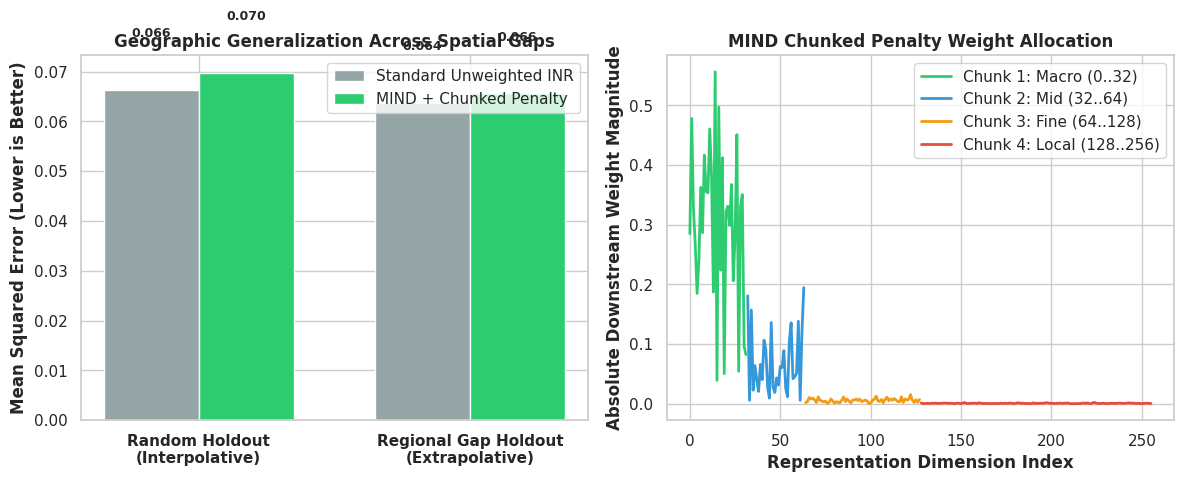

MIND benchmark visualization saved successfully as mind_geographic_inr_results.png.


In [4]:
# [CELL 4 - Benchmark Evaluation & Multi-Panel Visualization]

def evaluate_model(model: DownstreamPredictor, inr: MINDGeographicINR, coords: torch.Tensor, targets: torch.Tensor, test_indices: torch.Tensor) -> float:
    inr.eval()
    model.eval()
    with torch.no_grad():
        emb = inr(coords[test_indices])
        preds = model(emb)
        mse = nn.functional.mse_loss(preds, targets[test_indices]).item()
    return mse

# 1. Random Holdout Evaluation
model_rand_standard, _ = train_downstream_model(mind_inr, coords, targets, tr_rand, use_chunked_penalty=False)
model_rand_chunked, _ = train_downstream_model(mind_inr, coords, targets, tr_rand, use_chunked_penalty=True)
mse_rand_std = evaluate_model(model_rand_standard, mind_inr, coords, targets, te_rand)
mse_rand_chk = evaluate_model(model_rand_chunked, mind_inr, coords, targets, te_rand)

# 2. Regional Gap Holdout Evaluation
model_gap_standard, _ = train_downstream_model(mind_inr, coords, targets, tr_gap, use_chunked_penalty=False)
model_gap_chunked, _ = train_downstream_model(mind_inr, coords, targets, tr_gap, use_chunked_penalty=True)
mse_gap_std = evaluate_model(model_gap_standard, mind_inr, coords, targets, te_gap)
mse_gap_chk = evaluate_model(model_gap_chunked, mind_inr, coords, targets, te_gap)

print("\n--- MIND Geographic INR Benchmark Summary ---")
print(f"Random Holdout MSE   | Standard L2: {mse_rand_std:.4f} | Chunked Penalty: {mse_rand_chk:.4f}")
print(f"Regional Gap MSE     | Standard L2: {mse_gap_std:.4f} | Chunked Penalty: {mse_gap_chk:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Random Holdout vs Regional Gap MSE
categories = ['Random Holdout\n(Interpolative)', 'Regional Gap Holdout\n(Extrapolative)']
std_scores = [mse_rand_std, mse_gap_std]
chk_scores = [mse_rand_chk, mse_gap_chk]

x = np.arange(len(categories))
width = 0.35

rects1 = ax1.bar(x - width/2, std_scores, width, label='Standard Unweighted INR', color='#95a5a6')
rects2 = ax1.bar(x + width/2, chk_scores, width, label='MIND + Chunked Penalty', color='#2ecc71')

ax1.set_title("Geographic Generalization Across Spatial Gaps", fontweight='bold')
ax1.set_ylabel("Mean Squared Error (Lower is Better)", fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(categories, fontweight='bold')
ax1.legend(frameon=True)

for rect in rects1 + rects2:
    height = rect.get_height()
    ax1.text(rect.get_x() + rect.get_width()/2.0, height + 0.01, f"{height:.3f}", ha='center', va='bottom', fontweight='bold', fontsize=9)

# Plot 2: Weight Norm Distribution Across Matryoshka Chunks
w_std = torch.abs(model_gap_standard.linear.weight.detach().cpu().squeeze())
w_chk = torch.abs(model_gap_chunked.linear.weight.detach().cpu().squeeze())

ax2.plot(range(32), w_chk[:32].numpy(), color='#2ecc71', linewidth=2, label='Chunk 1: Macro (0..32)')
ax2.plot(range(32, 64), w_chk[32:64].numpy(), color='#3498db', linewidth=2, label='Chunk 2: Mid (32..64)')
ax2.plot(range(64, 128), w_chk[64:128].numpy(), color='#f39c12', linewidth=2, label='Chunk 3: Fine (64..128)')
ax2.plot(range(128, 256), w_chk[128:256].numpy(), color='#e74c3c', linewidth=2, label='Chunk 4: Local (128..256)')

ax2.set_title("MIND Chunked Penalty Weight Allocation", fontweight='bold')
ax2.set_xlabel("Representation Dimension Index", fontweight='bold')
ax2.set_ylabel("Absolute Downstream Weight Magnitude", fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig("mind_geographic_inr_results.png", dpi=300)
plt.show()

print("MIND benchmark visualization saved successfully as mind_geographic_inr_results.png.")